In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("product_segmentation_task_1.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1348, 18)


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link,Cluster,Hierarchical_Cluster
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,"₹1,099",64,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,1,2
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,₹349,43,4.0,43994.0,"Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...,1,1
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,"₹1,899",90,3.9,7928.0,【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...,1,0
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,₹699,53,4.2,94363.0,The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...,1,2
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,₹399,61,4.2,16905.0,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...,1,0


In [7]:
# Select columns required for Task 2
cols = [
    'discount_percentage',
    'rating',
    'discounted_price',
    'rating_count',
    'category'
]

# Check data types
print("Data Types:")
print(df[cols].dtypes)

# Check missing values
print("\nMissing Values:")
print(df[cols].isnull().sum())

# Check rating and discount ranges
print("\nMinimum and Maximum Values:")
print(df[['rating', 'discount_percentage']].agg(['min', 'max']))

Data Types:
discount_percentage      int64
rating                 float64
discounted_price       float64
rating_count           float64
category                   str
dtype: object

Missing Values:
discount_percentage    0
rating                 0
discounted_price       0
rating_count           0
category               0
dtype: int64

Minimum and Maximum Values:
     rating  discount_percentage
min     2.0                    0
max     5.0                   94


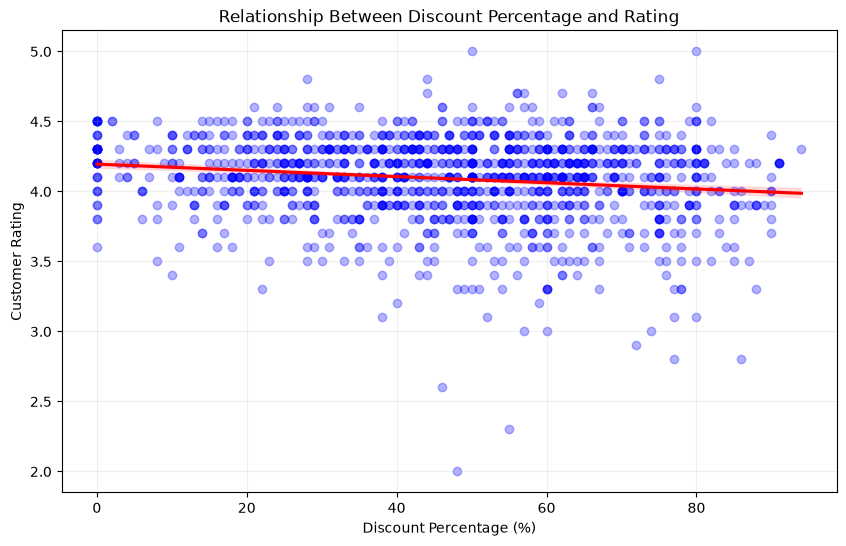

In [8]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='discount_percentage',
    y='rating',
    scatter_kws={'alpha': 0.3, 'color': 'blue'},
    line_kws={'color': 'red'}
)

plt.title('Relationship Between Discount Percentage and Rating')
plt.xlabel('Discount Percentage (%)')
plt.ylabel('Customer Rating')
plt.grid(alpha=0.2)

plt.show()

In [9]:
# Define discount ranges
bins = [-0.01, 20, 50, 75, 100]

labels = [
    'Low (0-20%)',
    'Medium (20-50%)',
    'High (50-75%)',
    'Very High (75-100%)'
]

# Create discount groups
df['discount_group'] = pd.cut(
    df['discount_percentage'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Check product distribution
df['discount_group'].value_counts().sort_index()

discount_group
Low (0-20%)            175
Medium (20-50%)        567
High (50-75%)          480
Very High (75-100%)    126
Name: count, dtype: int64

In [10]:
discount_summary = (
    df.groupby('discount_group', observed=True)
      .agg(
          product_count=('product_id', 'count'),
          average_rating=('rating', 'mean'),
          median_rating=('rating', 'median')
      )
      .reset_index()
)

discount_summary

,discount_group,product_count,average_rating,median_rating
0,Low (0-20%),175,4.168571,4.2
1,Medium (20-50%),567,4.110935,4.1
2,High (50-75%),480,4.067292,4.1
3,Very High (75-100%),126,3.994444,4.0


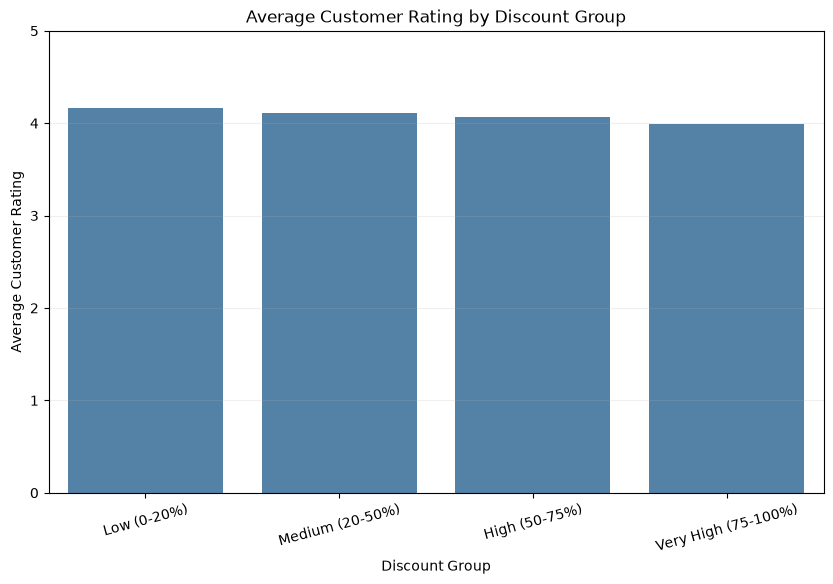

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=discount_summary,
    x='discount_group',
    y='average_rating',
    color='steelblue'
)

plt.title('Average Customer Rating by Discount Group')
plt.xlabel('Discount Group')
plt.ylabel('Average Customer Rating')

plt.ylim(0, 5)
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.2)

plt.show()

In [12]:
from scipy.stats import pearsonr, spearmanr

pearson_corr, pearson_p = pearsonr(
    df['discount_percentage'],
    df['rating']
)

spearman_corr, spearman_p = spearmanr(
    df['discount_percentage'],
    df['rating']
)

print("Pearson Correlation:", round(pearson_corr, 4))
print("Pearson P-value:", round(pearson_p, 4))

print("Spearman Correlation:", round(spearman_corr, 4))
print("Spearman P-value:", round(spearman_p, 4))

Pearson Correlation: -0.1622
Pearson P-value: 0.0
Spearman Correlation: -0.1499
Spearman P-value: 0.0


### Correlation Analysis — Findings

Pearson correlation analysis revealed a weak negative relationship between discount percentage and customer rating (r = -0.1622).

Spearman rank correlation also indicated a weak negative association (ρ = -0.1499), supporting the overall direction of the relationship.

Both tests produced statistically significant p-values (p < 0.0001, based on the rounded output), leading to rejection of the null hypothesis of zero correlation at the 5% significance level.

These results suggest that products with higher discounts tend to have slightly lower customer ratings. However, the relationship is weak, and statistical significance does not imply practical importance or causation.


In [13]:
#multiple regression analysis
print(f"Pearson p-value: {pearson_p:.3e}")
print(f"Spearman p-value: {spearman_p:.3e}")

Pearson p-value: 2.111e-09
Spearman p-value: 3.182e-08


In [14]:
print("Total Unique Categories:", df['category'].nunique())

print("\nTop 10 Categories:")
print(df['category'].value_counts().head(10))

print("\nSample Category:")
print(df['category'].iloc[0])

Total Unique Categories: 211

Top 10 Categories:
category
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables                        159
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones                                      68
Electronics|WearableTechnology|SmartWatches                                                               62
Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions                                             60
Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear                                              51
Electronics|HomeTheater,TV&Video|Accessories|RemoteControls                                               49
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|MixerGrinders                                  27
Computers&Accessories|Accessories&Peripherals|Keyboards,Mice&InputDevices|Mice                            24
Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Irons,Stea

In [15]:
# Extract main category
df['main_category'] = (
    df['category']
    .str.split('|', regex=False)
    .str[0]
    .str.strip()
)

# Check unique main categories
print("Unique Main Categories:", df['main_category'].nunique())

# Count products in each main category
print("\nProducts per Main Category:")
print(df['main_category'].value_counts())

Unique Main Categories: 9

Products per Main Category:
main_category
Electronics              490
Home&Kitchen             447
Computers&Accessories    373
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64


In [16]:
#preparing values for multiple regression
# Create log-transformed variables
df['log_price'] = np.log1p(df['discounted_price'])

df['log_rating_count'] = np.log1p(df['rating_count'])

# Compare original and transformed variables
df[
    [
        'discounted_price',
        'log_price',
        'rating_count',
        'log_rating_count'
    ]
].head(10)

,discounted_price,log_price,rating_count,log_rating_count
0,399.00,5.991465,24269.0,10.096996
1,199.00,5.298317,43994.0,10.691831
2,199.00,5.298317,7928.0,8.978282
3,329.00,5.799093,94363.0,11.454915
4,154.00,5.043425,16905.0,9.735424
5,149.00,5.010635,24871.0,10.121498
6,176.63,5.179703,15188.0,9.628327
7,229.00,5.438079,30411.0,10.322593
8,499.00,6.214608,179691.0,12.099000
9,199.00,5.298317,43994.0,10.691831


In [17]:
import statsmodels.formula.api as smf

# Multiple Linear Regression
model = smf.ols(
    formula="""
        rating ~ discount_percentage
               + log_price
               + log_rating_count
               + C(main_category)
    """,
    data=df
).fit(cov_type='HC3')

# Display regression results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 rating   R-squared:                       0.124
Model:                            OLS   Adj. R-squared:                  0.116
Method:                 Least Squares   F-statistic:                     14.25
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           2.79e-26
Time:                        11:42:18   Log-Likelihood:                -178.38
No. Observations:                1348   AIC:                             380.8
Df Residuals:                    1336   BIC:                             443.2
Df Model:                          11                                         
Covariance Type:                  HC3                                         
                                                coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

In [18]:
category_counts = df['main_category'].value_counts()

print(category_counts)

print("\nCategories with fewer than 20 products:")
print(category_counts[category_counts < 20])

main_category
Electronics              490
Home&Kitchen             447
Computers&Accessories    373
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64

Categories with fewer than 20 products:
main_category
MusicalInstruments     2
HomeImprovement        2
Toys&Games             1
Car&Motorbike          1
Health&PersonalCare    1
Name: count, dtype: int64


In [19]:
# Identify categories with at least 20 products
major_categories = category_counts[category_counts >= 20].index

# Group rare categories into 'Other'
df['category_grouped'] = np.where(
    df['main_category'].isin(major_categories),
    df['main_category'],
    'Other'
)

# Verify new groups
print(df['category_grouped'].value_counts())

category_grouped
Electronics              490
Home&Kitchen             447
Computers&Accessories    373
OfficeProducts            31
Other                      7
Name: count, dtype: int64


In [20]:
model_v2 = smf.ols(
    formula="""
        rating ~ discount_percentage
               + log_price
               + log_rating_count
               + C(category_grouped)
    """,
    data=df
).fit(cov_type='HC3')

print("R-squared:", round(model_v2.rsquared, 4))
print("Adjusted R-squared:", round(model_v2.rsquared_adj, 4))

print("\nDiscount Coefficient:")
print(model_v2.summary2().tables[1].loc['discount_percentage'])

R-squared: 0.1209
Adjusted R-squared: 0.1163

Discount Coefficient:
Coef.      -0.001273
Std.Err.    0.000424
z          -3.001938
P>|z|       0.002683
[0.025     -0.002103
0.975]     -0.000442
Name: discount_percentage, dtype: float64


In [21]:
from scipy.stats import pearsonr

# Analyze categories with at least 20 products
category_results = []

for category in major_categories:
    subset = df[df['main_category'] == category]

    corr, p_value = pearsonr(
        subset['discount_percentage'],
        subset['rating']
    )

    category_results.append({
        'Category': category,
        'Products': len(subset),
        'Pearson_Correlation': round(corr, 4),
        'P_Value': round(p_value, 6)
    })

category_analysis = pd.DataFrame(category_results)

print(category_analysis)

                Category  Products  Pearson_Correlation   P_Value
0            Electronics       490              -0.1925  0.000018
1           Home&Kitchen       447              -0.2391  0.000000
2  Computers&Accessories       373              -0.1006  0.052240
3         OfficeProducts        31              -0.1351  0.468676


In [22]:
# Step 10: Category Interaction Regression

import statsmodels.formula.api as smf

interaction_model = smf.ols(
    formula="""
        rating ~ discount_percentage * C(category_grouped)
               + log_price
               + log_rating_count
    """,
    data=df
).fit(cov_type='HC3')

# Compare original and interaction models
print("WITHOUT INTERACTION")
print("Adjusted R²:", round(model_v2.rsquared_adj, 4))
print("AIC:", round(model_v2.aic, 2))

print("\nWITH INTERACTION")
print("Adjusted R²:", round(interaction_model.rsquared_adj, 4))
print("AIC:", round(interaction_model.aic, 2))

# Display discount and interaction coefficients
print("\nDISCOUNT & CATEGORY INTERACTION RESULTS")

print(
    interaction_model.summary2().tables[1]
    .filter(like='discount_percentage', axis=0)
)

WITHOUT INTERACTION
Adjusted R²: 0.1163
AIC: 376.79

WITH INTERACTION
Adjusted R²: 0.1207
AIC: 374.11

DISCOUNT & CATEGORY INTERACTION RESULTS
                                                       Coef.  Std.Err.  \
discount_percentage                                -0.000002  0.000814   
discount_percentage:C(category_grouped)[T.Elect... -0.000731  0.000984   
discount_percentage:C(category_grouped)[T.Home&... -0.003141  0.001162   
discount_percentage:C(category_grouped)[T.Offic... -0.001615  0.001963   
discount_percentage:C(category_grouped)[T.Other]   -0.001426  0.017222   

                                                           z     P>|z|  \
discount_percentage                                -0.002073  0.998346   
discount_percentage:C(category_grouped)[T.Elect... -0.742746  0.457635   
discount_percentage:C(category_grouped)[T.Home&... -2.702135  0.006890   
discount_percentage:C(category_grouped)[T.Offic... -0.822669  0.410696   
discount_percentage:C(category_grouped)[T.

In [23]:
# Step 11.1: Identify influential observations

influence = model_v2.get_influence()

cooks_distance = influence.cooks_distance[0]

threshold = 4 / len(df)

print("Cook's Distance Threshold:", round(threshold, 6))

print("Number of Influential Observations:",
      (cooks_distance > threshold).sum())

# View top influential observations
df_influence = df.copy()
df_influence['cooks_distance'] = cooks_distance

df_influence[
    [
        'product_id',
        'discount_percentage',
        'rating',
        'discounted_price',
        'rating_count',
        'category_grouped',
        'cooks_distance'
    ]
].sort_values(
    'cooks_distance',
    ascending=False
).head(10)

Cook's Distance Threshold: 0.002967
Number of Influential Observations: 71


,product_id,discount_percentage,rating,discounted_price,rating_count,category_grouped,cooks_distance
876,B07R99NBVB,58,4.5,249.0,5985.0,Other,0.076562
1192,B0BPJBTB3F,48,2.0,1299.0,2.0,Home&Kitchen,0.058427
723,B07JF9B592,32,3.8,478.0,20218.0,Other,0.027773
1127,B0BFBNXS94,55,2.3,669.0,13.0,Home&Kitchen,0.027252
174,B0BP7XLX48,80,5.0,399.0,5.0,Computers&Accessories,0.023288
1041,B0912WJ87V,42,3.8,2339.0,1118.0,Other,0.019811
1239,B0B7L86YCB,46,2.6,161.0,24.0,Home&Kitchen,0.018563
699,B09ZHCJDP1,50,5.0,499.0,23.0,Computers&Accessories,0.014156
829,B00DJ5N9VK,0,4.3,150.0,15867.0,Other,0.014004
520,B0BBVKRP7B,86,2.8,281.0,87.0,Electronics,0.013151


In [24]:
# Keep observations below Cook's Distance threshold
df_filtered = df.loc[cooks_distance <= threshold].copy()

# Refit the same regression model
model_filtered = smf.ols(
    formula="""
        rating ~ discount_percentage
               + log_price
               + log_rating_count
               + C(category_grouped)
    """,
    data=df_filtered
).fit(cov_type='HC3')

# Compare results
comparison = pd.DataFrame({
    'Model': ['Original', 'Without Influential Observations'],
    'Observations': [int(model_v2.nobs), int(model_filtered.nobs)],
    'Discount_Coefficient': [
        model_v2.params['discount_percentage'],
        model_filtered.params['discount_percentage']
    ],
    'P_Value': [
        model_v2.pvalues['discount_percentage'],
        model_filtered.pvalues['discount_percentage']
    ],
    'Adjusted_R2': [
        model_v2.rsquared_adj,
        model_filtered.rsquared_adj
    ]
})

print(comparison.to_string(index=False))

                           Model  Observations  Discount_Coefficient  P_Value  Adjusted_R2
                        Original          1348             -0.001273 0.002683     0.116318
Without Influential Observations          1277             -0.001437 0.000043     0.148320


In [26]:
# Final project completion summary

print("TASK 2: DISCOUNT–RATING RELATIONSHIP ANALYSIS")
print("=" * 48)

print("Products analyzed:", len(df))
print("Pearson correlation:", round(pearson_corr, 4))
print("Spearman correlation:", round(spearman_corr, 4))

print("Adjusted regression coefficient:",
      round(model_v2.params['discount_percentage'], 6))

print("Regression p-value:",
      round(model_v2.pvalues['discount_percentage'], 6))

print("Adjusted R-squared:",
      round(model_v2.rsquared_adj, 4))

print("\nTASK 2 ANALYSIS COMPLETED")

TASK 2: DISCOUNT–RATING RELATIONSHIP ANALYSIS
Products analyzed: 1348
Pearson correlation: -0.1622
Spearman correlation: -0.1499
Adjusted regression coefficient: -0.001273
Regression p-value: 0.002683
Adjusted R-squared: 0.1163

TASK 2 ANALYSIS COMPLETED


# Task 2: Discount–Rating Relationship Analysis

## Objective

To investigate the relationship between product discount percentages and customer ratings using exploratory data analysis, correlation tests, multiple regression, category-level analysis, and outlier sensitivity testing.

## Dataset

The analysis was conducted on 1,348 cleaned Amazon product records.

## Key Findings

### 1. Discount Group Analysis

Products in the low-discount group (0–20%) had the highest average customer rating among the discount groups examined.

### 2. Correlation Analysis

- Pearson correlation: **−0.1622** (p = 2.111 × 10⁻⁹)
- Spearman correlation: **−0.1499** (p = 3.182 × 10⁻⁸)

Both tests indicated a statistically significant but weak negative association between discount percentage and customer rating.

### 3. Multiple Regression Analysis

A multiple linear regression model was developed using discount percentage as the main predictor while controlling for log-transformed discounted price, log-transformed rating count, and grouped product categories.

- Discount coefficient: **−0.001273**
- P-value: **0.002683**
- Adjusted R²: **0.1163**

A 10-percentage-point increase in discount was associated with approximately 0.0127 lower rating points, holding the included control variables constant.

### 4. Category-Level Analysis

Home & Kitchen showed the strongest negative Pearson correlation among the four major categories (r = −0.2391).

An interaction regression found that the discount–rating slope for Home & Kitchen differed significantly from the reference category, Computers & Accessories (interaction p = 0.00689).

### 5. Outlier Sensitivity Analysis

Using Cook's Distance, 71 potentially influential observations were identified.

After temporarily excluding these observations:

- Remaining products: **1,277**
- Discount coefficient: **−0.001437**
- P-value: **0.000043**
- Adjusted R²: **0.1483**

The negative association remained statistically significant, although its estimated magnitude changed.

## Business Recommendations

1. Avoid assuming that higher discounts automatically lead to higher customer satisfaction.
2. Evaluate discount strategies separately across product categories, particularly Home & Kitchen.
3. Consider customer ratings alongside product quality, price, popularity, and other business metrics when evaluating discount strategies.
4. Conduct controlled experiments before making causal claims about how discounts affect customer ratings.

## Limitations

- The dataset does not contain actual sales, profit, or conversion data.
- Correlation and regression results do not establish causation.
- The regression explains a relatively small proportion of customer-rating variation.
- Some product categories contain few observations.
- Multiple category comparisons are exploratory.
- The sensitivity analysis excludes potentially influential observations for diagnostic purposes, not because those records are necessarily invalid.

## Final Conclusion

The analysis provides evidence of a statistically significant but weak negative relationship between product discount percentage and customer rating. This association remains after adjusting for selected product characteristics and is broadly consistent with the sensitivity analysis.

Discount percentage alone is not a strong predictor of customer satisfaction. Businesses should assess discount strategies alongside product category, customer feedback, and additional commercial performance indicators.